# Boston House Price Prediction with Machine Learning (Python, scikit-learn)
Rishabh Aryan · Capstone for the 6-Month Joint Certification Program in AI & ML by NIELIT Ropar with IIT Ropar.

Data: the Boston housing data (Harrison, D. & Rubinfeld, D. L. (1978). *Hedonic housing prices and the demand for clean air*. Journal of Environmental Economics and Management 5, 81–102), 506 census tracts, 1970. Target `MEDV` = median value of owner-occupied homes in $1000s.

**Ethics:** the column `B` = 1000(Bk − 0.63)², where Bk is the proportion of Black residents by town. It encodes race and is **excluded from every model**; one comparison below only *measures* how much it changes accuracy.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import RepeatedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.compose import TransformedTargetRegressor, ColumnTransformer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
SEED = 42
sns.set_theme(style="whitegrid")
FEATURES = ["CRIM","ZN","INDUS","CHAS","NOX","RM","AGE","DIS","RAD","TAX","PTRATIO","LSTAT"]  # B excluded
TARGET = "MEDV"
def make(loss="huber", alpha=0.9):
    return GradientBoostingRegressor(loss=loss, alpha=alpha, n_estimators=300, learning_rate=0.05, max_depth=3,
                                     min_samples_leaf=5, subsample=0.8, random_state=SEED)
df = pd.read_csv("data/boston_housing.csv"); X, y = df[FEATURES], df[TARGET]
df.shape

(506, 14)

## 1. Exploratory data analysis

In [2]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
CRIM,506.0,3.614,8.602,0.006,0.082,0.257,3.677,88.976
ZN,506.0,11.364,23.322,0.000,0.000,0.000,12.500,100.000
INDUS,506.0,11.137,6.860,0.460,5.190,9.690,18.100,27.740
CHAS,506.0,0.069,0.254,0.000,0.000,0.000,0.000,1.000
NOX,506.0,0.555,0.116,0.385,0.449,0.538,0.624,0.871
RM,506.0,6.285,0.703,3.561,5.885,6.208,6.624,8.780
AGE,506.0,68.575,28.149,2.900,45.025,77.500,94.075,100.000
DIS,506.0,3.795,2.106,1.130,2.100,3.207,5.188,12.126
RAD,506.0,9.549,8.707,1.000,4.000,5.000,24.000,24.000
TAX,506.0,408.237,168.537,187.000,279.000,330.000,666.000,711.000


missing: 0 | duplicates: 0 | MEDV == 50 (censored cap): 16


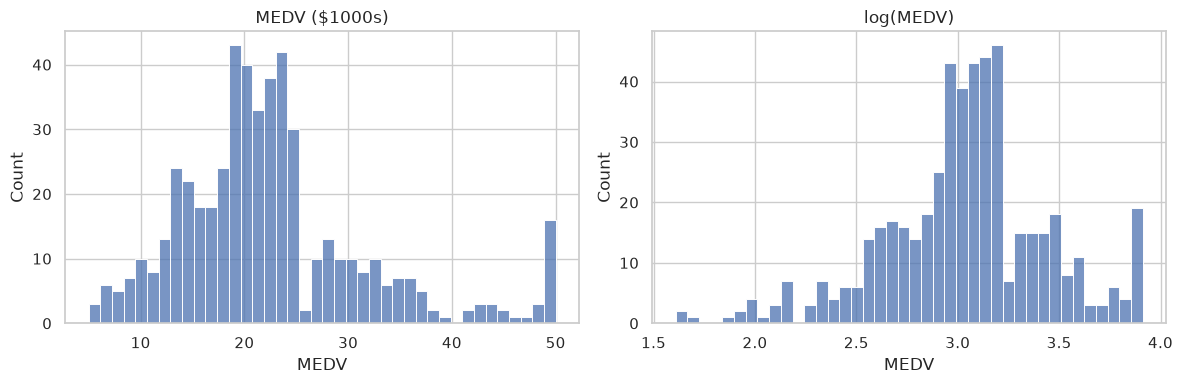

In [3]:
print("missing:", int(df.isna().sum().sum()), "| duplicates:", int(df.duplicated().sum()), "| MEDV == 50 (censored cap):", int((y == 50).sum()))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(y, bins=40, ax=ax[0]).set_title("MEDV ($1000s)"); sns.histplot(np.log(y), bins=40, ax=ax[1]).set_title("log(MEDV)")
plt.tight_layout(); plt.show()

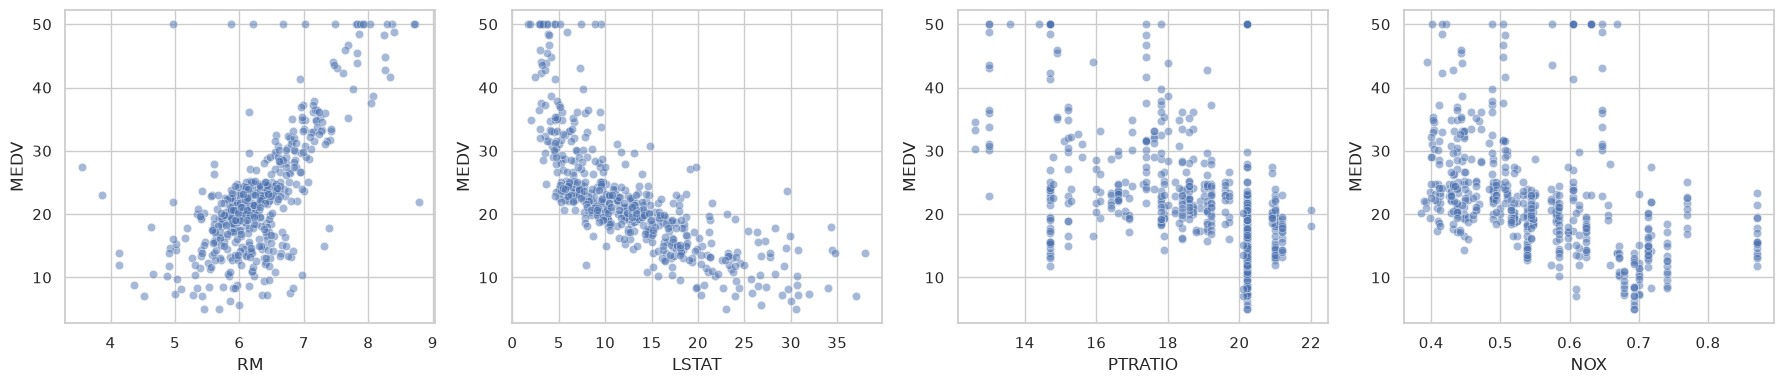

In [4]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, f in zip(ax, ["RM", "LSTAT", "PTRATIO", "NOX"]): sns.scatterplot(x=df[f], y=y, alpha=.5, ax=a)
plt.tight_layout(); plt.show()

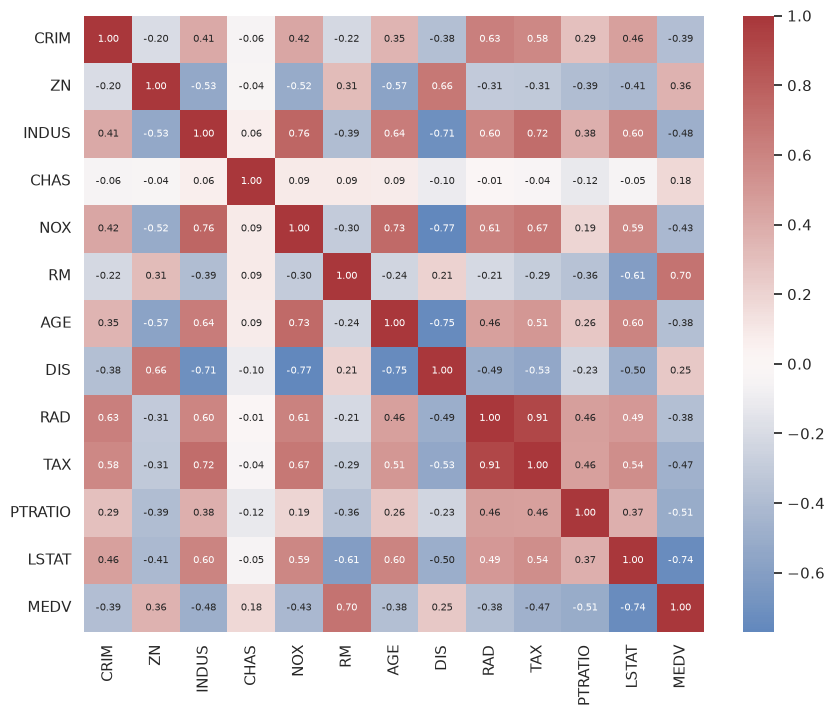

In [5]:
plt.figure(figsize=(10, 8)); sns.heatmap(df[FEATURES + [TARGET]].corr(), annot=True, fmt=".2f", cmap="vlag", center=0, annot_kws={"size": 7}); plt.show()

### Known issues with this dataset
* `B` encodes race (excluded, see above). `LSTAT` (% "lower status" population) is a socioeconomic variable; it is kept because it is the strongest legitimate predictor, but it is a neighbourhood-level proxy, not a property attribute.
* `MEDV` is censored at 50 (16 tracts), so the true values of the most expensive tracts are unknown.
* The data describe 1970 Boston; prices are not comparable with today's market.
* The dataset has been removed from scikit-learn's loaders because of these issues.

## 2. Model comparison — repeated 5-fold CV (5 repeats = 25 folds), metrics on the original scale

In [6]:
cv = RepeatedKFold(n_splits=5, n_repeats=5, random_state=SEED)
log = lambda m: TransformedTargetRegressor(m, func=np.log, inverse_func=np.exp)
logx = ColumnTransformer([("log", FunctionTransformer(np.log1p), ["CRIM", "LSTAT", "DIS"])], remainder="passthrough")
models = {
    "Mean baseline": DummyRegressor(),
    "Linear regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Ridge, log target + log features": log(make_pipeline(logx, StandardScaler(), Ridge(alpha=1.0))),
    "Random forest": RandomForestRegressor(n_estimators=500, min_samples_leaf=2, random_state=SEED, n_jobs=-1),
    "Random forest, log target": log(RandomForestRegressor(n_estimators=500, min_samples_leaf=2, random_state=SEED, n_jobs=-1)),
    "HistGradientBoosting, log target": log(HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, min_samples_leaf=10, random_state=SEED)),
    "GBR squared loss, log target": log(make("squared_error")),
    "GBR Huber loss, log target (deployed)": log(make("huber")),
}
def evaluate(m, X, y, skip=()):
    s = {"RMSE": [], "MAE": [], "R2": []}
    for tr, te in cv.split(X):
        te = np.array([i for i in te if i not in skip])
        p = m.fit(X.iloc[tr], y.iloc[tr]).predict(X.iloc[te])
        s["RMSE"].append(root_mean_squared_error(y.iloc[te], p)); s["MAE"].append(mean_absolute_error(y.iloc[te], p)); s["R2"].append(r2_score(y.iloc[te], p))
    return {**{f"{k} mean": np.mean(v) for k, v in s.items()}, **{f"{k} std": np.std(v) for k, v in s.items()}}
res = pd.DataFrame({n: evaluate(m, X, y) for n, m in models.items()}).T[["RMSE mean","RMSE std","MAE mean","MAE std","R2 mean","R2 std"]].sort_values("RMSE mean")
res.round(3)

,RMSE mean,RMSE std,MAE mean,MAE std,R2 mean,R2 std
"GBR squared loss, log target",3.109,0.423,2.116,0.221,0.880,0.030
"GBR Huber loss, log target (deployed)",3.157,0.414,2.119,0.202,0.877,0.030
"HistGradientBoosting, log target",3.330,0.501,2.208,0.240,0.863,0.035
Random forest,3.359,0.455,2.255,0.249,0.860,0.040
"Random forest, log target",3.514,0.453,2.290,0.239,0.848,0.037
"Ridge, log target + log features",4.248,0.509,2.978,0.291,0.778,0.052
Ridge,4.869,0.540,3.454,0.321,0.709,0.059
Linear regression,4.870,0.538,3.459,0.320,0.709,0.059
Mean baseline,9.174,0.850,6.668,0.646,-0.015,0.021


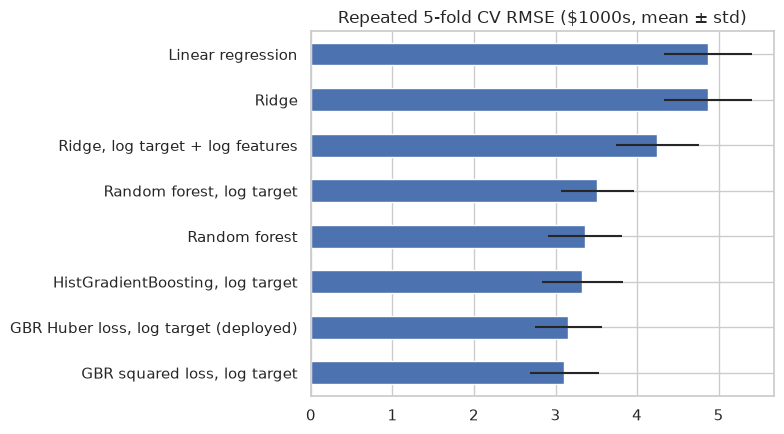

In [7]:
r = res.drop(index="Mean baseline").sort_values("RMSE mean")
ax = r["RMSE mean"].plot.barh(xerr=r["RMSE std"], figsize=(8, 4.5)); ax.set_title("Repeated 5-fold CV RMSE ($1000s, mean ± std)"); plt.tight_layout(); plt.show()

## 3. Robustness checks
### 3a. Censored tracts (MEDV = 50) not scored

In [8]:
cens = set(df.index[y == 50])
pd.DataFrame({n: evaluate(models[n], X, y, skip=cens) for n in ["Ridge, log target + log features", "Random forest, log target", "GBR squared loss, log target", "GBR Huber loss, log target (deployed)"]}).T[["RMSE mean","RMSE std","R2 mean"]].round(3)

,RMSE mean,RMSE std,R2 mean
"Ridge, log target + log features",3.567,0.308,0.786
"Random forest, log target",2.990,0.472,0.846
"GBR squared loss, log target",2.804,0.346,0.866
"GBR Huber loss, log target (deployed)",2.801,0.348,0.866


### 3b. What excluding `B` costs (measurement only — B is not used by the deployed model)

In [9]:
Xb = df[FEATURES + ["B"]]
pd.DataFrame({"without B (deployed)": evaluate(models["GBR Huber loss, log target (deployed)"], X, y),
              "with B (not used)": evaluate(models["GBR Huber loss, log target (deployed)"], Xb, y)}).T[["RMSE mean","RMSE std","R2 mean"]].round(3)

,RMSE mean,RMSE std,R2 mean
without B (deployed),3.157,0.414,0.877
with B (not used),3.130,0.464,0.879


## 4. Prediction range — 5% / 95% quantile GBR on log(MEDV), coverage under CV

In [10]:
cov, width = [], []
for tr, te in cv.split(X):
    lo = make("quantile", 0.05).fit(X.iloc[tr], np.log(y.iloc[tr])).predict(X.iloc[te])
    hi = make("quantile", 0.95).fit(X.iloc[tr], np.log(y.iloc[tr])).predict(X.iloc[te])
    yt = y.iloc[te].to_numpy(); cov.append(np.mean((yt >= np.exp(lo)) & (yt <= np.exp(hi)))); width.append(np.median(np.exp(hi) - np.exp(lo)))
print(f"nominal 90%: empirical coverage {np.mean(cov):.3f} ± {np.std(cov):.3f}; median width {np.mean(width):.2f}")

nominal 90%: empirical coverage 0.769 ± 0.045; median width 6.97


## 5. Hold-out diagnostics and permutation importance (deployed model)

hold-out RMSE 2.932 | MAE 1.918 | R2 0.883


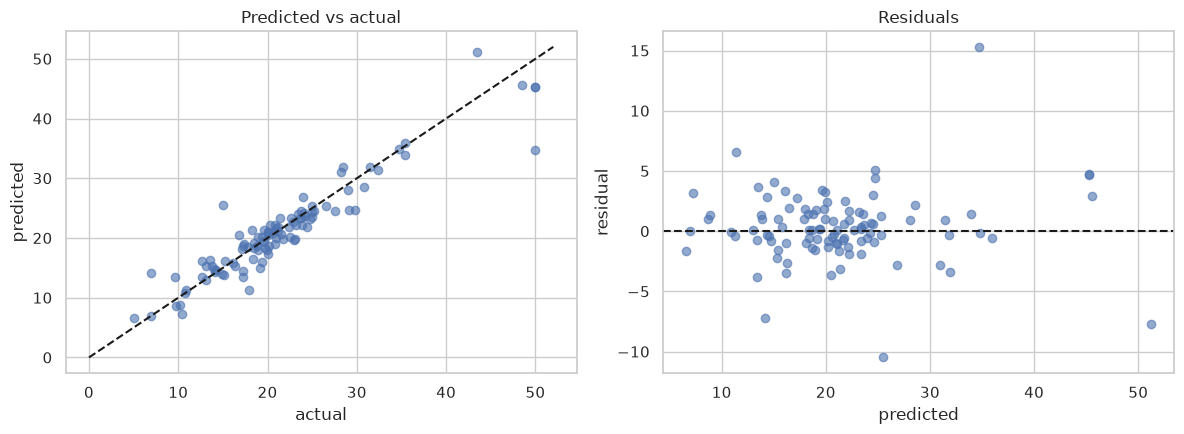

In [11]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED)
best = models["GBR Huber loss, log target (deployed)"].fit(X_tr, y_tr); p = best.predict(X_te)
print(f"hold-out RMSE {root_mean_squared_error(y_te,p):.3f} | MAE {mean_absolute_error(y_te,p):.3f} | R2 {r2_score(y_te,p):.3f}")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(y_te, p, alpha=.6); ax[0].plot([0, 52], [0, 52], "k--"); ax[0].set(xlabel="actual", ylabel="predicted", title="Predicted vs actual")
ax[1].scatter(p, y_te - p, alpha=.6); ax[1].axhline(0, color="k", ls="--"); ax[1].set(xlabel="predicted", ylabel="residual", title="Residuals")
plt.tight_layout(); plt.show()

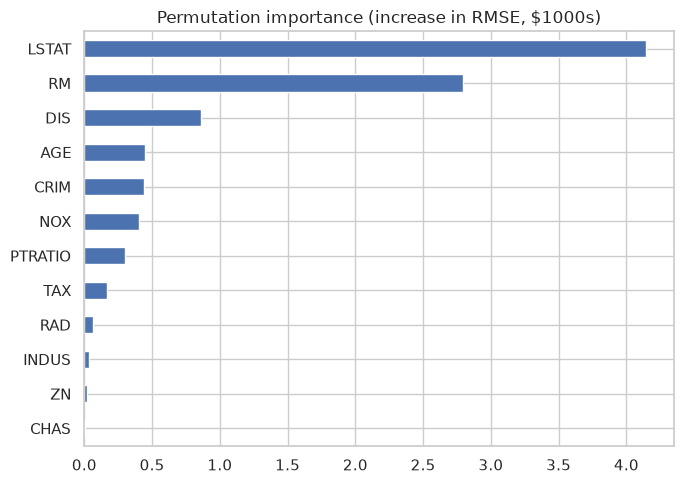

LSTAT      4.144
RM         2.797
DIS        0.864
AGE        0.447
CRIM       0.439
NOX        0.403
PTRATIO    0.300
TAX        0.168
RAD        0.064
INDUS      0.032
ZN         0.017
CHAS       0.003
dtype: float64

In [12]:
imp = permutation_importance(best, X_te, y_te, n_repeats=50, random_state=SEED, scoring="neg_root_mean_squared_error")
pi = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
pi.plot.barh(figsize=(7, 5), title="Permutation importance (increase in RMSE, $1000s)"); plt.tight_layout(); plt.show()
pi.sort_values(ascending=False).round(3)

## 6. Secondary dataset: 3-feature version (RM, LSTAT, PTRATIO; 489 rows, MEDV in dollars)
The second attached file is a common teaching subset with outliers/censored rows removed and MEDV rescaled. Same CV, for reference only.

In [13]:
d3 = pd.read_csv("data/boston_housing_3features.csv"); X3, y3 = d3[["RM","LSTAT","PTRATIO"]], d3["MEDV"]
print(d3.shape)
pd.DataFrame({n: evaluate(models[n], X3, y3) for n in ["Mean baseline", "Ridge", "Random forest, log target", "GBR Huber loss, log target (deployed)"]}).T[["RMSE mean","RMSE std","R2 mean","R2 std"]].round(3)

(489, 4)


,RMSE mean,RMSE std,R2 mean,R2 std
Mean baseline,165338.525,12863.238,-0.022,0.023
Ridge,88569.602,6433.417,0.704,0.041
"Random forest, log target",67896.601,6210.445,0.825,0.030
"GBR Huber loss, log target (deployed)",67383.673,5757.979,0.828,0.031


## 7. Conclusions
* Gradient boosting on a log target is best: squared loss RMSE 3.109 ± 0.423 (R² 0.880) and the deployed Huber model 3.157 ± 0.414 (R² 0.877) — a tie within one standard deviation; Huber was chosen for robustness. Ridge reaches 4.869 (R² 0.709); log features and log target help it (4.248).
* Not scoring the 16 censored tracts (MEDV = 50) lowers the deployed model's RMSE to 2.801.
* Removing `B` costs almost nothing: RMSE 3.157 without vs 3.130 with it — well within fold-to-fold noise.
* LSTAT and RM dominate permutation importance (4.144 and 2.797), then DIS (0.864).
* The 5%/95% quantile models cover 76.9% of tracts in CV, below the nominal 90%: treat the range as indicative.
* On the 3-feature teaching subset the same ranking holds (deployed model R² 0.828 vs ridge 0.704).